# 01 — AnnData, QC, normalization, PCA/UMAP

Goals:
1. Get to know the AnnData structure of the CITE-seq file.
2. Quality control: recompute QC metrics from raw counts and compare with the provided ones.
3. Normalize RNA ourselves (library size + log1p) instead of using the provided size factors
   (see notebook 00).
4. PCA and UMAP for exploration; look at cell-type, site and donor structure.

**Leakage note.** Library-size normalization, log1p and the per-cell CLR of the proteins
are computed per cell and learn nothing from other cells, so they are safe to apply to
all cells. HVG selection and PCA in this notebook are exploratory only. They are **not**
reused as model inputs: from Phase 3 on they are refit on the training split.

In [1]:
import os, sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.utils.sparsefuncs import mean_variance_axis

from citeseq.paths import CITE_H5AD, FIGURES_DIR, PROCESSED_DIR
from citeseq.io import load_cite, split_modalities, csr_nbytes
from citeseq.labels import to_lineage, LINEAGE_ORDER
from citeseq import plotting as P

SEED = 0
P.set_style()
sc.settings.verbosity = 1

# Optional quick test on a random subset: CITESEQ_SUBSET=5000
SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
FIG_DIR = FIGURES_DIR if SUBSET is None else PROCESSED_DIR / "test_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("subset:", SUBSET, "| figures ->", FIG_DIR)

subset: None | figures -> /Users/ardaqas/aa/results/figures


## 1. Load raw counts only

The file holds two full matrices (`X` and `layers['counts']`). We load only the raw counts,
streamed from disk in chunks, so memory is roughly halved.

In [2]:
mask = None
if SUBSET:
    rng = np.random.default_rng(SEED)
    mask = np.zeros(90_261, dtype=bool)
    mask[rng.choice(mask.size, SUBSET, replace=False)] = True

t0 = time.time()
adata = load_cite(CITE_H5AD, matrix="layers/counts", cell_mask=mask)
print(f"loaded in {time.time() - t0:.0f}s, counts matrix uses {csr_nbytes(adata.X) / 1e9:.2f} GB")
adata

loaded in 6s, counts matrix uses 1.13 GB


/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 90261 × 14087
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    uns: 'source_matrix'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'

## 2. A tour of the AnnData object

`X` is cells x features. `obs` and `var` are tables aligned to its rows and columns.
RNA (GEX) and protein (ADT) share one matrix here; we split them into two objects.
Splitting also makes the 36 feature names that appear as both a gene and a protein
(e.g. `CD14`) unique within each object.

In [3]:
rna, adt = split_modalities(adata)
del adata
print(rna)
print(adt)
print("\nX is a", type(rna.X).__name__, "with", f"{rna.X.nnz:,}", "stored values;",
      f"{rna.X.nnz / np.prod(rna.shape):.1%} of the entries are non-zero")

AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    uns: 'source_matrix'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
AnnData object with n_obs × n_vars = 90261 × 134
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodTy

In [4]:
# Slicing keeps X, obs and var aligned: first 5 cells x 6 proteins, as a small dense table
pd.DataFrame(adt.X[:5, :6].toarray(), index=adt.obs_names[:5], columns=adt.var_names[:6])

,CD86,CD274,CD270,CD155,CD112,CD47
GCATTAGCATAAGCGG-1-s1d1,1.0,1.0,16.0,0.0,3.0,103.0
TACAGGTGTTAGAGTA-1-s1d1,55.0,7.0,38.0,29.0,23.0,280.0
AGGATCTAGGTCTACT-1-s1d1,0.0,2.0,23.0,0.0,2.0,72.0
GTAGAAAGTGACACAG-1-s1d1,0.0,1.0,13.0,4.0,85.0,79.0
TCCGAAAAGGATCATA-1-s1d1,1.0,7.0,12.0,4.0,9.0,129.0


In [5]:
rna.obs[["cell_type", "batch", "DonorNumber", "Site", "is_train"]].head()

,cell_type,batch,DonorNumber,Site,is_train
GCATTAGCATAAGCGG-1-s1d1,Naive CD20+ B IGKC+,s1d1,donor1,site1,train
TACAGGTGTTAGAGTA-1-s1d1,CD14+ Mono,s1d1,donor1,site1,train
AGGATCTAGGTCTACT-1-s1d1,Naive CD20+ B IGKC+,s1d1,donor1,site1,train
GTAGAAAGTGACACAG-1-s1d1,HSC,s1d1,donor1,site1,train
TCCGAAAAGGATCATA-1-s1d1,Reticulocyte,s1d1,donor1,site1,train


## 3. Quality control

We recompute the standard metrics from the raw counts:
* `total_counts`: UMIs per cell (library size)
* `n_genes_by_counts`: genes detected
* `pct_counts_mt`: share of UMIs from mitochondrial genes (names starting with `MT-`)

Then we check that they agree with the provided columns.

In [6]:
rna.var["mt"] = rna.var_names.str.startswith("MT-")
print("mitochondrial genes:", rna.var["mt"].sum())
sc.pp.calculate_qc_metrics(rna, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

# The provided QC columns were most likely computed before genes were filtered down to
# 13,953, so ours use a smaller gene set. Expected direction: fewer genes detected and a
# slightly higher mitochondrial share (smaller denominator).
o = rna.obs
d_genes = o["n_genes_by_counts"] - o["GEX_n_genes_by_counts"]
d_mt = o["pct_counts_mt"] - o["GEX_pct_counts_mt"]
print("genes detected, ours - provided: median", d_genes.median(), "| ours <= provided in all cells:", bool((d_genes <= 0).all()))
print("% mito, ours - provided: median", round(d_mt.median(), 3), "| ours >= provided in all cells:", bool((d_mt >= -1e-6).all()))
print("correlation, genes detected:", round(np.corrcoef(o["n_genes_by_counts"], o["GEX_n_genes_by_counts"])[0, 1], 4),
      "| % mito:", round(np.corrcoef(o["pct_counts_mt"], o["GEX_pct_counts_mt"])[0, 1], 4))
adt_total = np.asarray(adt.X.sum(axis=1)).ravel()
print("ADT 134-protein total <= ADT_total_counts (which also counts isotypes):",
      bool(np.all(adt_total <= o["ADT_total_counts"].to_numpy() + 1e-6)))

qc = rna.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt",
              "ADT_total_counts", "ADT_iso_count"]]
qc.describe(percentiles=[.01, .5, .99]).T

mitochondrial genes: 13


genes detected, ours - provided: median -10.0 | ours <= provided in all cells: True
% mito, ours - provided: median 0.02 | ours >= provided in all cells: True
correlation, genes detected: 1.0 | % mito: 0.9998
ADT 134-protein total <= ADT_total_counts (which also counts isotypes): True


,count,mean,std,min,1%,50%,99%,max
total_counts,90261.0,5643.558594,5959.522949,496.0,832.600000,3917.000000,31558.400000,61673.000000
n_genes_by_counts,90261.0,1455.264621,897.713117,50.0,176.000000,1317.000000,4909.400000,7470.000000
pct_counts_mt,90261.0,6.542067,3.203968,0.0,0.187171,6.342183,16.857307,24.030584
ADT_total_counts,90261.0,2935.444092,3620.084717,200.0,268.000000,1384.000000,17498.600000,39576.000000
ADT_iso_count,90261.0,12.324658,11.461179,0.0,1.000000,8.000000,51.000000,246.000000


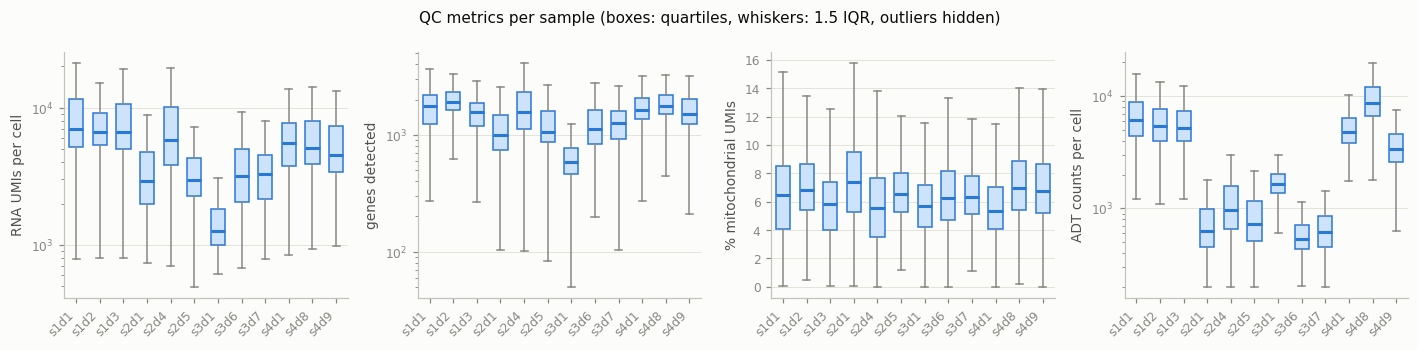

In [7]:
batches = sorted(rna.obs["batch"].unique())
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
P.boxplot_by_group(axes[0], rna.obs["total_counts"], rna.obs["batch"], batches, log=True, ylabel="RNA UMIs per cell")
P.boxplot_by_group(axes[1], rna.obs["n_genes_by_counts"], rna.obs["batch"], batches, log=True, ylabel="genes detected")
P.boxplot_by_group(axes[2], rna.obs["pct_counts_mt"], rna.obs["batch"], batches, ylabel="% mitochondrial UMIs")
P.boxplot_by_group(axes[3], rna.obs["ADT_total_counts"], rna.obs["batch"], batches, log=True, ylabel="ADT counts per cell")
fig.suptitle("QC metrics per sample (boxes: quartiles, whiskers: 1.5 IQR, outliers hidden)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "phase1_qc_per_batch.png")

## 4. Normalization of RNA

**Library size.** Divide each cell by its total UMIs and multiply by 10,000 (CP10k), so
cells captured at different depths become comparable.

**log1p.** Count variance grows with the mean, so without a log the most highly
expressed genes dominate every distance and every PCA axis. The plot below shows this:
on the raw scale variance rises steeply with mean; after log1p the trend is much flatter.

In [8]:
rna.layers["counts"] = rna.X  # same object, no copy
norm = sc.pp.normalize_total(rna, target_sum=1e4, inplace=False)["X"]
# gene mean/variance on the CP10k scale, BEFORE log1p (log1p below works in place)
mean_raw, var_raw = mean_variance_axis(norm, axis=0)
rna.X = norm
sc.pp.log1p(rna)  # in place on X
del norm
print("log-normalized X: max", rna.X.max(), "| memory", f"{csr_nbytes(rna.X) / 1e9:.2f} GB")

# Library-size factor (mean 1) vs the provided scran size factor
lib_sf = rna.obs["total_counts"] / rna.obs["total_counts"].mean()
print("Spearman(library size factor, provided scran size factor):",
      round(lib_sf.corr(rna.obs["GEX_size_factors"], method="spearman"), 3))

log-normalized X: max 9.116692 | memory 1.05 GB
Spearman(library size factor, provided scran size factor): 0.511


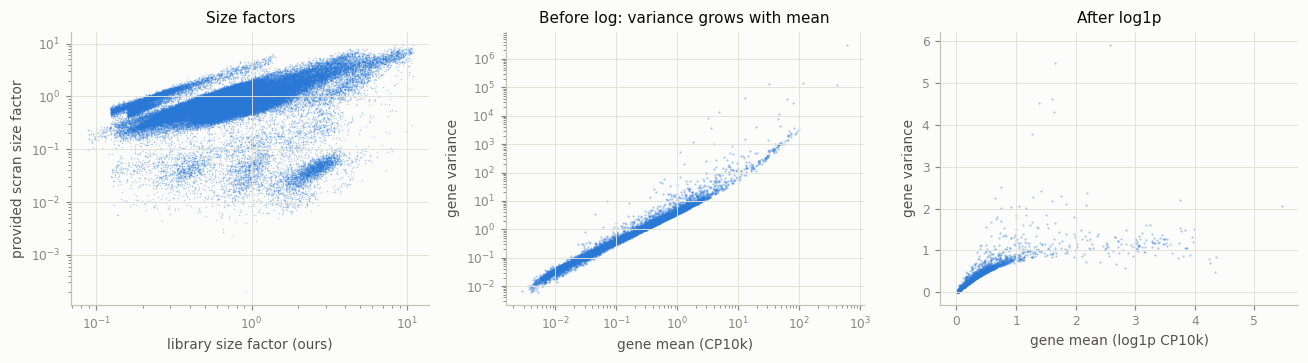

In [9]:
mean_log, var_log = mean_variance_axis(rna.X, axis=0)      # CP10k + log1p
keep = mean_raw > 0

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ax = axes[0]
ax.scatter(lib_sf, rna.obs["GEX_size_factors"], s=1, c=P.BLUE, alpha=0.3, linewidths=0, rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("library size factor (ours)"); ax.set_ylabel("provided scran size factor")
ax.set_title("Size factors")
ax = axes[1]
ax.scatter(mean_raw[keep], var_raw[keep], s=2, c=P.BLUE, alpha=0.4, linewidths=0, rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("gene mean (CP10k)"); ax.set_ylabel("gene variance")
ax.set_title("Before log: variance grows with mean")
ax = axes[2]
ax.scatter(mean_log[keep], var_log[keep], s=2, c=P.BLUE, alpha=0.4, linewidths=0, rasterized=True)
ax.set_xlabel("gene mean (log1p CP10k)"); ax.set_ylabel("gene variance")
ax.set_title("After log1p")
fig.tight_layout()
fig.savefig(FIG_DIR / "phase1_normalization.png")

## 5. Highly variable genes and PCA (exploratory)

HVGs are selected per sample (`batch_key="batch"`) and combined, so genes that vary only
because of one sample are less likely to be chosen. PCA runs directly on the sparse
log-normalized HVG matrix (centering is done implicitly). We skip unit-variance
scaling, because scaling would turn the matrix into a dense one.

HVGs: 2000 | variance explained by PC1-10: 0.409 | PC1-50: 0.503


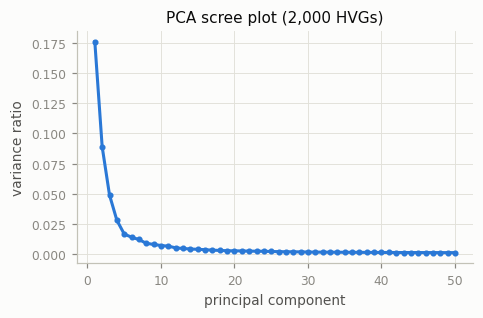

In [10]:
sc.pp.highly_variable_genes(rna, n_top_genes=2000, batch_key="batch", flavor="seurat")
hvg = rna[:, rna.var["highly_variable"]].copy()
sc.pp.pca(hvg, n_comps=50, svd_solver="arpack", random_state=SEED)
vr = hvg.uns["pca"]["variance_ratio"]
print("HVGs:", hvg.n_vars, "| variance explained by PC1-10:", vr[:10].sum().round(3), "| PC1-50:", vr.sum().round(3))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(np.arange(1, 51), vr, color=P.BLUE, lw=2, marker="o", ms=3)
ax.set_xlabel("principal component"); ax.set_ylabel("variance ratio")
ax.set_title("PCA scree plot (2,000 HVGs)")
fig.tight_layout()
fig.savefig(FIG_DIR / "phase1_pca_scree.png")

In [11]:
t0 = time.time()
sc.pp.neighbors(hvg, n_neighbors=15, n_pcs=30, random_state=SEED)
sc.tl.umap(hvg, random_state=SEED)
print(f"neighbors + UMAP: {time.time() - t0:.0f}s")
rna.obsm["X_pca"] = hvg.obsm["X_pca"]
rna.obsm["X_umap"] = hvg.obsm["X_umap"]

/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


neighbors + UMAP: 121s


## 6. Cell types, sites and donors on the UMAP

Each panel highlights one group in blue over all cells in grey. If a site or donor covers
all the clusters, cells mix across that group in this embedding. If it sits apart, there is
a sample-specific signal (biological or technical). The lineage groups are our own coarse
grouping of the 45 labels, for plotting only.

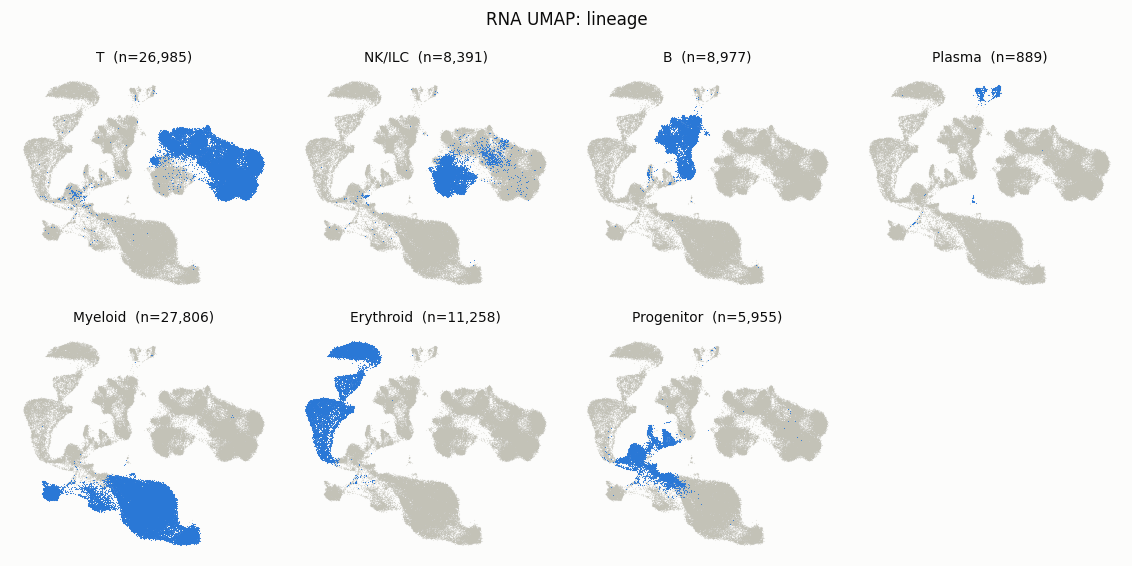

In [12]:
rna.obs["lineage"] = pd.Categorical(to_lineage(rna.obs["cell_type"]), categories=LINEAGE_ORDER)
xy = rna.obsm["X_umap"]
fig = P.highlight_grid(xy, rna.obs["lineage"], LINEAGE_ORDER, ncols=4, suptitle="RNA UMAP: lineage")
fig.savefig(FIG_DIR / "phase1_umap_lineage.png")

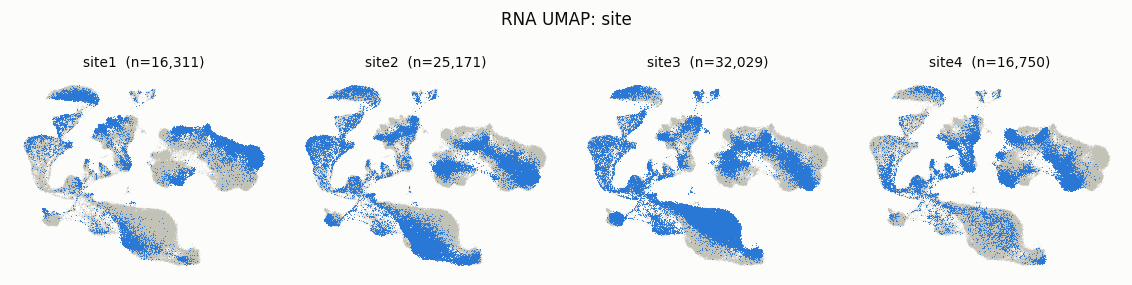

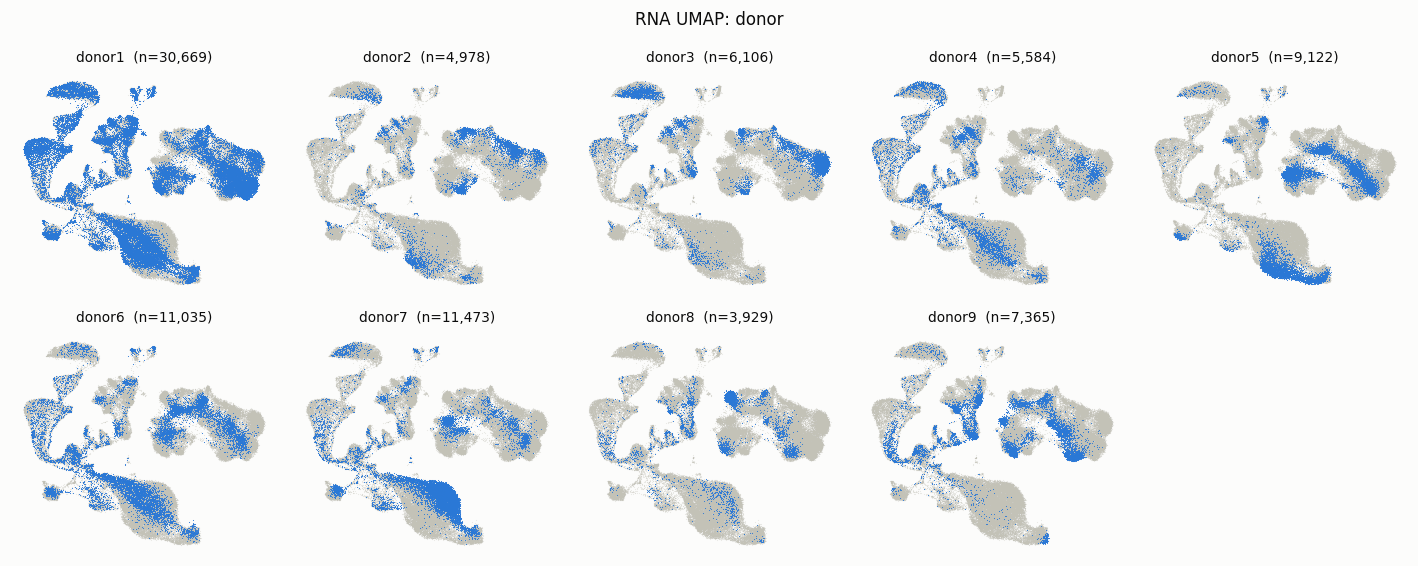

In [13]:
fig = P.highlight_grid(xy, rna.obs["Site"], sorted(rna.obs["Site"].unique()), ncols=4, suptitle="RNA UMAP: site")
fig.savefig(FIG_DIR / "phase1_umap_site.png")
donors = sorted(rna.obs["DonorNumber"].unique(), key=lambda d: int(d.replace("donor", "")))
fig = P.highlight_grid(xy, rna.obs["DonorNumber"], donors, ncols=5, suptitle="RNA UMAP: donor")
fig.savefig(FIG_DIR / "phase1_umap_donor.png")

## 7. Cell type x donor

The within-cell-type metrics in later phases need enough cells of a type in the test
donors. How many types reach a minimum count in every donor?

In [14]:
ct_donor = pd.crosstab(rna.obs["cell_type"], rna.obs["DonorNumber"])[donors]
ct_donor = ct_donor.loc[ct_donor.sum(axis=1).sort_values(ascending=False).index]
for k in (20, 50, 100):
    print(f"cell types with >= {k:>3} cells in every donor: {(ct_donor.min(axis=1) >= k).sum()} / {len(ct_donor)}")
ct_donor

cell types with >=  20 cells in every donor: 12 / 45
cell types with >=  50 cells in every donor: 7 / 45
cell types with >= 100 cells in every donor: 2 / 45


DonorNumber,donor1,donor2,donor3,donor4,donor5,donor6,donor7,donor8,donor9
cell_type,,,,,,,,,
CD14+ Mono,7244,726,309,1294,2561,2927,6056,466,110
CD4+ T activated,2464,848,547,364,1009,544,380,134,676
CD4+ T naive,2738,304,833,266,631,349,219,87,470
NK,971,458,271,76,1128,415,1242,268,605
Reticulocyte,1656,279,929,580,116,244,291,50,127
Erythroblast,2202,57,228,471,61,524,307,35,154
Naive CD20+ B IGKC+,1663,150,265,629,129,105,88,243,718
CD8+ T naive,1069,129,878,89,73,157,116,193,403
CD16+ Mono,865,142,28,129,692,248,353,31,147


In [15]:
# Share of each donor's cells per lineage: does the composition differ between donors?
comp = pd.crosstab(rna.obs["DonorNumber"], rna.obs["lineage"], normalize="index")[LINEAGE_ORDER].loc[donors]
(comp * 100).round(1)

lineage,T,NK/ILC,B,Plasma,Myeloid,Erythroid,Progenitor
DonorNumber,,,,,,,
donor1,28.8,6.2,11.2,1.5,30.5,16.5,5.2
donor2,45.2,13.5,9.0,0.3,20.0,8.1,3.9
donor3,50.4,5.1,12.7,0.1,6.7,21.5,3.5
donor4,17.0,3.0,14.0,0.3,28.9,22.7,14.1
donor5,32.3,21.5,4.0,0.5,38.6,2.1,0.8
donor6,27.2,8.6,5.0,1.6,35.4,10.8,11.4
donor7,9.1,11.1,3.6,1.1,61.9,7.5,5.7
donor8,46.8,7.3,15.9,0.3,14.5,7.1,8.1
donor9,41.2,11.5,21.4,0.3,4.5,9.3,11.8


In [16]:
# Save per-cell results for later phases (UMAP is for plotting only)
out = rna.obs[["cell_type", "lineage", "batch", "DonorNumber", "Site",
               "total_counts", "n_genes_by_counts", "pct_counts_mt"]].copy()
out[["umap1", "umap2"]] = rna.obsm["X_umap"]
if SUBSET is None:
    out.to_csv(PROCESSED_DIR / "phase1_cells.csv.gz")
print(out.shape)

(90261, 10)


In [17]:
import resource, platform
# Peak memory of this kernel process (ru_maxrss is bytes on macOS, KiB on Linux)
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_gb = peak / 1e9 if platform.system() == "Darwin" else peak * 1024 / 1e9
print(f"peak memory of this notebook: {peak_gb:.2f} GB")

peak memory of this notebook: 4.54 GB


## Findings (full data, 90,261 cells)

**QC.** Recomputed metrics agree with the provided ones in the expected direction (provided
columns were most likely computed before gene filtering; consistent but not directly
verifiable). RNA depth varies between samples (median UMIs per cell from ~1,300 in `s3d1`
to ~7,000 in `s1d1`).

**Protein depth depends strongly on site (verified).** ADT counts per cell are about 5-10x
lower at site2 and site3. donor1 was measured at all four sites, so it works as a
within-donor control: its median 134-protein total is 6,073 (site1), 627 (site2), 1,623 (site3)
and 4,762 (site4). The donor is the same, so this difference is technical (site/batch). Per-cell CLR
removes the overall scale, but other site-specific differences (e.g. background) may remain.
This matters for the donor-based split in Phase 5, where a held-out donor is also mostly a
held-out site.

**Size factors.** The provided scran size factors form separate groups at 0.01-0.1 for cells
with ordinary library sizes, which supports normalizing from counts ourselves. Why this
happened is not known.

**Normalization.** On the CP10k scale gene variance rises over ~10 orders of magnitude with the
mean; after log1p the trend is much flatter. The genes that still have high variance after log1p
are expected to be cell-type markers. We have not checked which genes they are.

**PCA/UMAP.** PC1-10 explain 41% and PC1-50 explain 50% of the variance of the 2,000 HVGs.
The lineages form coherent regions; progenitors lie between the erythroid and myeloid regions,
as expected for differentiation. Every site covers all major lineages, but within the T and
myeloid regions individual donors occupy distinct sub-regions. This could be donor biology,
site effects, or both; with this design they cannot be separated, except for donor1.

**Composition differs a lot between donors.** For example, myeloid cells are 4.5% of donor9's
cells and 61.9% of donor7's. Pooled (all-cell) correlations therefore depend on the composition of
the test set, which is one reason to also report within-cell-type metrics.

**Cell type x donor.** Only 12 of 45 types have >= 20 cells in every donor (7 types reach >= 50,
2 reach >= 100). Some labels occur in a single donor (cDC1 and T prog cycling only in donor7;
CD8+ T naive CD127+ CD26- CD101- only in donor2). If such a donor is held out, the type is
missing from training.

Peak memory: 4.5 GB. Runtime: ~3 min.